In [3]:
%pip install keras

Note: you may need to restart the kernel to use updated packages.


In [4]:
import keras

In [5]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
y_train, y_test = y_train.ravel(), y_test.ravel()

/var/folders/8j/f0xtldm91_1c2bpdr69fxgzw0000gn/T/ipykernel_31547/2330884305.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 10))


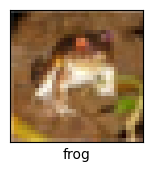

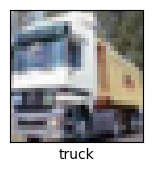

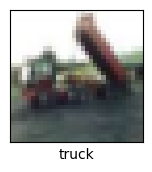

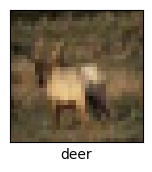

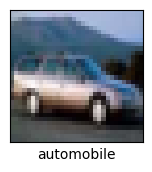

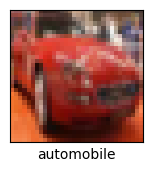

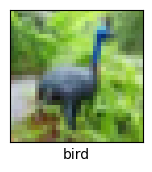

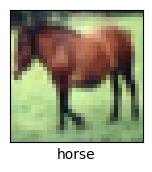

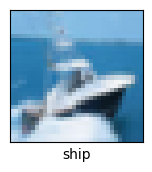

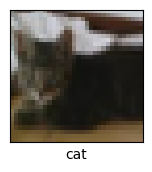

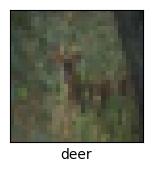

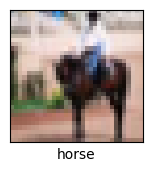

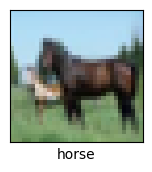

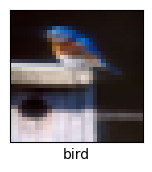

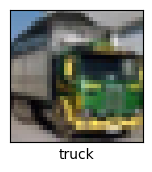

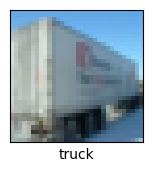

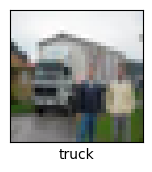

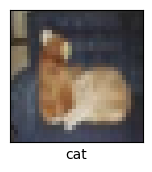

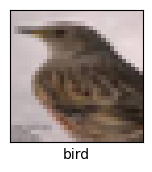

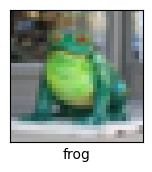

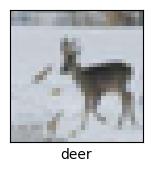

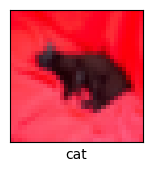

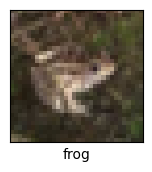

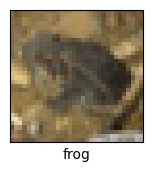

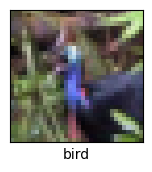

In [9]:
# Codifica las etiquetas de clase como texto de acuerdo con la clase correspondiente
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

for i in range(25):
    plt.figure(figsize=(10, 10))
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i])
    plt.xlabel(class_names[y_train[i]])

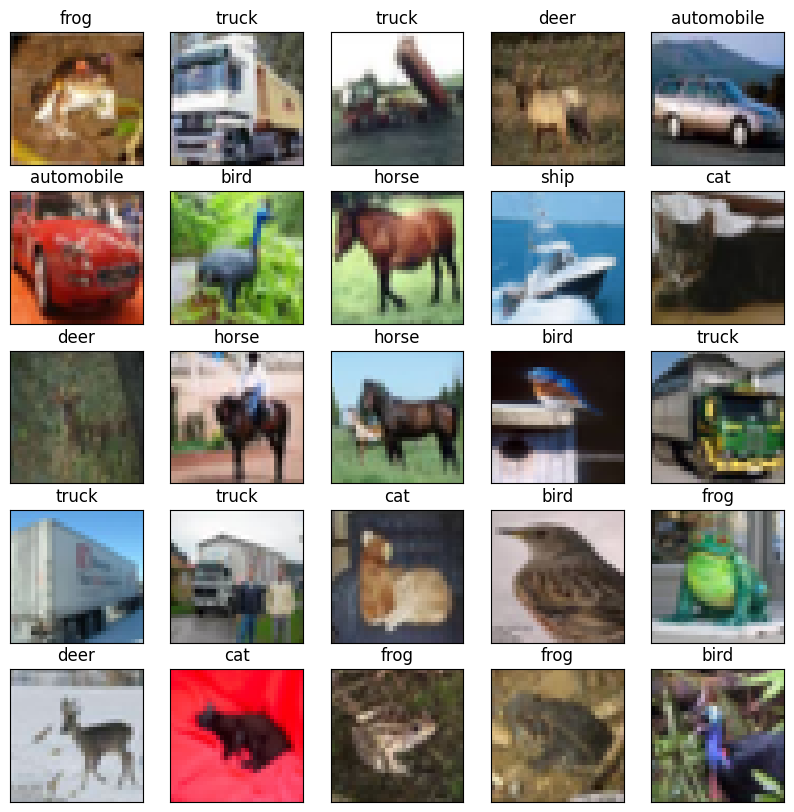

In [12]:
# Visualización de algunas imágenes de entrenamiento con sus etiquetas correspondientes codificadas en texto
from matplotlib import pyplot as plt

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])

In [13]:
# Aplana las imágenes de 32x32x3 a vectores de 3072 dimensiones
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

In [14]:
# Creamos un clasificador kNN utilizando la clase KNeighborsClassifier de scikit-learn
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)

# Entrenamos el clasificador kNN con los datos de entrenamiento
knn.fit(X_train_flat, y_train)

# Evaluamos el clasificador kNN en los datos de prueba
accuracy_knn = knn.score(X_test_flat, y_test)
print(f'Accuracy del clasificador kNN: {accuracy_knn:.2f}')

Accuracy del clasificador kNN: 0.33


In [15]:
# Creamos un clasificador MLP utilizando la clase MLPClassifier de scikit-learn
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=20)

# Entrenamos el clasificador MLP con los datos de entrenamiento
mlp.fit(X_train_flat, y_train)

# Evaluamos el clasificador MLP en los datos de prueba
accuracy_mlp = mlp.score(X_test_flat, y_test)
print(f'Accuracy del clasificador MLP: {accuracy_mlp:.2f}')

Accuracy del clasificador MLP: 0.45


/Users/eugenio/Documents/ComputerVision/.venv/lib/python3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# Creamos una CNN utilizando la clase Sequential de Keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# Compilamos el modelo
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Entrenamos la CNN con los datos de entrenamiento
model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test))

# Evaluamos la CNN en los datos de prueba
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f'Accuracy de la CNN: {test_accuracy:.2f}')

/Users/eugenio/Documents/ComputerVision/.venv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.3532 - loss: 1.7434 - val_accuracy: 0.5733 - val_loss: 1.2015
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5761 - loss: 1.1947 - val_accuracy: 0.6128 - val_loss: 1.1042
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6453 - loss: 1.0150 - val_accuracy: 0.6615 - val_loss: 0.9617
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6783 - loss: 0.9069 - val_accuracy: 0.6844 - val_loss: 0.9125
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7066 - loss: 0.8289 - val_accuracy: 0.6620 - val_loss: 0.9800
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7290 - loss: 0.7708 - val_accuracy: 0.6840 - val_loss: 0.9080
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7495 - loss: 0.7162 - val_accuracy: 0.7064 - val_loss: 0.8598
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7625 - loss: 0.6731 - 